# 06 · Decision Framework

The guide this whole project builds toward. It reuses the results saved by the
earlier notebooks (`outputs/data/*.json`) and turns them into a one-page answer to
"which recommender should I use?" — plus the honest caveat that offline wins can be
hollow.

In [1]:
# --- make the notebook runnable from anywhere: find the repo root, add to path, chdir ---
import os
import sys
from pathlib import Path

_root = Path.cwd()
while not (_root / "pyproject.toml").exists() and _root != _root.parent:
    _root = _root.parent
sys.path.insert(0, str(_root))
os.chdir(_root)

%matplotlib inline
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 120)

from src.artifacts import save_figure, save_json
from src.config import get_settings

SETTINGS = get_settings()
print("project root:", _root)
print("seed:", SETTINGS.seed, "| top_k:", SETTINGS.top_k)

project root: /workspaces/recommender_101
seed: 42 | top_k: 10


In [2]:
# Reuse saved results; recompute the arena only if a notebook hasn't been run yet.
from pathlib import Path

def load_or_none(name):
    p = Path("outputs/data") / f"{name}.json"
    return json.loads(p.read_text()) if p.exists() else None

board_json = load_or_none("04_scoreboard")
if board_json is None:
    from src.data.ratings import load_movielens
    from src.evaluation.comparison import run_arena
    from src.evaluation.splits import leave_last_out
    from src.recommenders import build_default_recommenders
    data = load_movielens()
    split = leave_last_out(data.matrix, n_holdout=SETTINGS.split.n_holdout,
                           min_train=SETTINGS.split.min_train, timestamps=data.timestamps, seed=SETTINGS.seed)
    board = run_arena(build_default_recommenders(item_features=data.item_features, settings=SETTINGS),
                      split, k=SETTINGS.top_k, item_features=data.item_features)
else:
    board = pd.DataFrame(board_json).T

cold = load_or_none("05_coldstart_summary") or {}
board.round(4)

,precision@k,recall@k,ndcg@k,map,coverage,novelty,pop_bias,diversity
popularity,0.0072,0.0361,0.0209,0.0120,0.0125,1.4271,231.6143,0.7003
user_knn,0.0123,0.0615,0.0356,0.0210,0.0313,1.8497,183.3970,0.6972
item_knn,0.0138,0.0689,0.0400,0.0236,0.0745,2.4656,130.3716,0.6821
matrix_factorization,0.0021,0.0107,0.0065,0.0037,0.0568,4.7759,50.2967,0.6343
content,0.0007,0.0033,0.0013,0.0004,0.1517,7.1502,11.9828,0.1091


## The headline, restated honestly

- **Report popularity first.** It is strong: it beats our explicit-rating matrix
  factorization on every accuracy metric, and is competitive overall.
- **Neighbourhood CF (item-based) is the accuracy winner** on this data — not the
  fanciest method. Matrix factorization *as a rating predictor* loses at top-N;
  making it win requires training for ranking (implicit/BPR), which is future work.
- **Popularity is the worst at discovery** (coverage, novelty, diversity), a cost
  the accuracy table hides.
- **Cold users break every personalized method**; popularity is the fallback until
  history accrues (CF overtakes after a single rating).

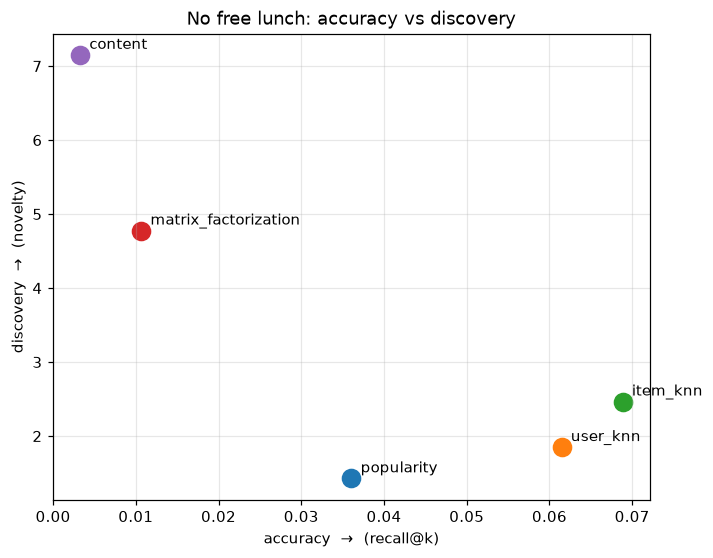

In [3]:
# The accuracy-vs-discovery trade-off, as a map you can point at.
fig, ax = plt.subplots(figsize=(7, 5.5))
for method in board.index:
    x, y = board.loc[method, "recall@k"], board.loc[method, "novelty"]
    ax.scatter(x, y, s=140)
    ax.annotate(method, (x, y), xytext=(6, 4), textcoords="offset points", fontsize=10)
ax.set_xlabel("accuracy  →  (recall@k)")
ax.set_ylabel("discovery  →  (novelty)")
ax.set_title("No free lunch: accuracy vs discovery")
ax.grid(alpha=0.3)
save_figure(fig, "06_tradeoff_map")
plt.show()

## The decision table

| Your situation | Use | Why |
|---|---|---|
| **Always, first** | **Popularity baseline** | The yardstick; it may already beat your fancy method. |
| Sparse data, few ratings/user | Item-based CF or content | Item similarities are stable; content needs no co-ratings. |
| Plenty of interactions, want accuracy | Neighbourhood CF (item-based); MF **if trained for ranking** | CF tops this data; explicit-rating MF does not. |
| New **user** (no history) | Popularity, then CF/MF as history builds | Cold start = explore–exploit. |
| New **item** (no ratings) | Content-based | Features let a never-rated item be recommended. |
| You care about discovery | CF / MF / content, **not** popularity-only | Popularity has the worst novelty & diversity. |

In [4]:
decision = [
    {"scenario": "always, first", "recommend": "popularity baseline",
     "why": "the yardstick; may already beat the fancy method"},
    {"scenario": "sparse data / few ratings per user", "recommend": "item-based CF or content",
     "why": "stable item similarities; content needs no co-ratings"},
    {"scenario": "plenty of interactions, want accuracy", "recommend": "item-based CF (MF if trained for ranking)",
     "why": "CF leads on this data; explicit-rating MF loses at top-N"},
    {"scenario": "new user, no history", "recommend": "popularity, then CF/MF as history builds",
     "why": "cold start is explore-exploit"},
    {"scenario": "new item, no ratings", "recommend": "content-based",
     "why": "features let a never-rated item be recommended"},
    {"scenario": "optimize for discovery", "recommend": "CF / MF / content (not popularity alone)",
     "why": "popularity has the worst novelty and diversity"},
]
save_json(decision, "06_decision_matrix")

summary = {
    "rule_zero": "Report the popularity baseline first, always.",
    "accuracy_winner": board[["precision@k", "recall@k", "ndcg@k", "map"]].mean(axis=1).idxmax(),
    "discovery_winner": board["novelty"].idxmax(),
    "worst_discovery": board["novelty"].idxmin(),
    "mf_beats_popularity_on_recall": bool(board.loc["matrix_factorization", "recall@k"] > board.loc["popularity", "recall@k"]),
    "cold_start_crossover_n": cold.get("user_knn_overtakes_popularity_at_n"),
    "offline_online_caveat": "Offline ranking wins are necessary but not sufficient: metrics reward recommending what the user would have found anyway.",
}
save_json(summary, "06_summary")
summary

{'rule_zero': 'Report the popularity baseline first, always.',
 'accuracy_winner': 'item_knn',
 'discovery_winner': 'content',
 'worst_discovery': 'popularity',
 'mf_beats_popularity_on_recall': False,
 'cold_start_crossover_n': 1,
 'offline_online_caveat': 'Offline ranking wins are necessary but not sufficient: metrics reward recommending what the user would have found anyway.'}

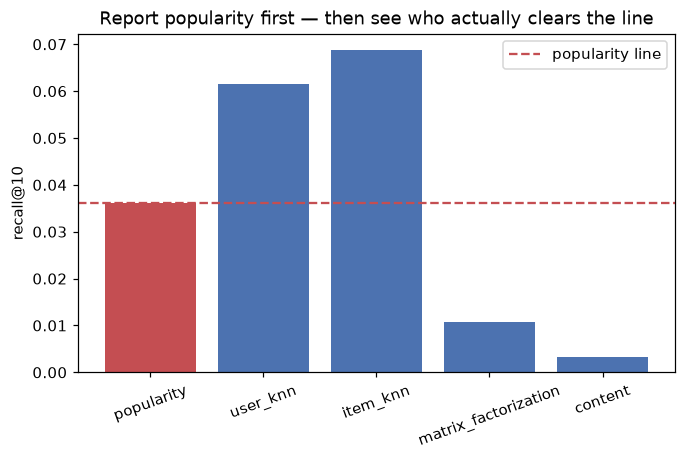

In [5]:
# Final picture: every method against the popularity line.
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(board.index, board["recall@k"], color=["#C44E52" if m == "popularity" else "#4C72B0" for m in board.index])
ax.axhline(board.loc["popularity", "recall@k"], linestyle="--", color="#C44E52", label="popularity line")
ax.set_ylabel(f"recall@{SETTINGS.top_k}")
ax.set_title("Report popularity first — then see who actually clears the line")
ax.tick_params(axis="x", rotation=20)
ax.legend()
save_figure(fig, "06_final_scoreboard")
plt.show()

## The honest closer: the offline–online gap

Everything here is **offline** evaluation: we held out interactions the user
already had and checked whether we would have ranked them highly. That rewards
recommending things the user *would have found anyway*. A recommender can win
offline and add no real value online — and a genuinely useful recommendation
(something the user would never have discovered) scores *zero* offline because it
was never in the held-out set. So an offline win is **necessary but not
sufficient**: it earns you an A/B test, not a victory lap.

You now have, in `src/`, from-scratch implementations of all five recommenders and
the ranking-evaluation harness — enough to run this honest comparison on your own
data. **Start it the way every honest recommender project should: report the
popularity baseline first.**